# Satellite-to-Satellite Validation: GRACE-FO

This notebook validates TAT-C's satellite-to-satellite analysis (`collect_space_observations`, see the [Space-Based Coverage](../examples/CollectSpace.ipynb) example) against the precise orbits of the two [GRACE-FO](https://gracefo.jpl.nasa.gov/) satellites over a week, 17 to 23 September 2026. The satellites follow each other in the same near-polar orbit, at an altitude of about 490 km and roughly 175 to 180 km apart, so the line of sight between them is always clear of the Earth, but its length and its minimum altitude vary around each orbit. A companion notebook, [Satellite-to-Satellite Validation: COSMIC-2](ValidateSpaceCOSMIC2.ipynb), validates the Earth's occlusion of the line of sight against radio occultations; this one validates the slant range constraints (`min_range` and `max_range`) and the occlusion constraint at an altitude well above the surface (`min_grazing_altitude`), and the orbit track positions they depend on:

1. **Orbits.** How closely do published orbits, as propagated by TAT-C (`collect_orbit_track` in Earth-fixed coordinates), reproduce each satellite's precise orbit?
2. **Range.** How accurately does TAT-C compute the range between the satellites?
3. **Range windows.** Does `collect_space_observations` find the periods when the range is within limits?
4. **Occlusion windows.** Does it find the periods when the line of sight stays above a given altitude?

## Reference Data

The GRACE-FO Level-1B data (`GRACEFO_L1B_ASCII_GRAV_JPL_RL04`, from [PO.DAAC](https://podaac.jpl.nasa.gov/), free [NASA Earthdata Login](https://urs.earthdata.nasa.gov/) account required) include each satellite's precise orbit (**GNV1B**), determined from its GPS receiver to a few centimeters: Earth-fixed positions and velocities every second, time-tagged in GPS seconds since 1 January 2000, 12:00. The daily archives (about 140 MB each) are downloaded once, and only the orbits of both satellites (GRACE-FO 1, identifier C, and GRACE-FO 2, identifier D) are kept, in a local `data/gracefo` directory.

TAT-C needs published orbits for the week: the two-line element sets (TLEs) of GRACE-FO 1 and 2 (NORAD 43476 and 43477), obtained from [Space-Track](https://www.space-track.org) (free account required) with the `gp_history` query

```
https://www.space-track.org/basicspacedata/query/class/gp_history/NORAD_CAT_ID/43476,43477/EPOCH/2026-09-14--2026-10-02/orderby/NORAD_CAT_ID%20asc,EPOCH%20asc/format/3le
```

and saved as `data/orbits/gracefo_gp_history.tle` (Space-Track's terms do not allow redistributing them, so the notebook raises an error if the file is missing). Element sets were published about every 6 to 8 hours (once a gap of 23 hours), for both satellites within about 25 s of each other. The week starts after a change in both satellites' mean motion on 15 to 17 September, apparently a maneuver.

In [1]:
import collections
import io
import tarfile
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data") / "gracefo"
DATA_DIR.mkdir(parents=True, exist_ok=True)
TLE_FILE = Path("data") / "orbits" / "gracefo_gp_history.tle"
if not TLE_FILE.exists():
    raise FileNotFoundError(f"download the GRACE-FO element sets from Space-Track to {TLE_FILE} (see above)")
DAYS = pd.date_range("2026-09-17", "2026-09-23", freq="D", tz="UTC")
J2000_GPS = datetime(2000, 1, 1, 12, tzinfo=timezone.utc)  # origin of GRACE-FO's GPS time
GPS_UTC_OFFSET = 18  # s, GPS time minus UTC in 2026
HEADER_END = "# End of YAML header"


def read_gnv1b(text):
    """GPS seconds (since 2000-01-01 12:00 GPS time), Earth-fixed positions (m, (3, N)), and Earth-fixed
    velocities (m/s, (3, N)) of the records of a GNV1B file."""
    records = np.loadtxt(io.StringIO(text.split(HEADER_END, 1)[1]), usecols=(0, 3, 4, 5, 9, 10, 11))
    return records[:, 0], records[:, 1:4].T, records[:, 4:7].T


def cache_path(day):
    return DATA_DIR / f"gnv1b_{day:%Y%m%d}.npz"


missing = [day for day in DAYS if not cache_path(day).exists()]
if missing:
    import earthaccess

    earthaccess.login()
    for day in missing:
        granules = [
            g
            for g in earthaccess.search_data(
                short_name="GRACEFO_L1B_ASCII_GRAV_JPL_RL04",
                temporal=(f"{day:%Y-%m-%d}T00:00:00", f"{day:%Y-%m-%d}T23:59:59"),
            )
            if g["umm"]["GranuleUR"] == f"gracefo_1B_{day:%Y-%m-%d}_RL04.ascii.noLRI"
        ]
        archive = Path(earthaccess.download(granules, str(DATA_DIR))[0])
        data = {}
        with tarfile.open(archive) as tar:
            for member in tar.getmembers():
                if member.name.startswith("GNV1B_") and member.name.endswith(".txt"):
                    satellite = member.name.split("_")[2]  # C (GRACE-FO 1) or D (GRACE-FO 2)
                    t, p, v = read_gnv1b(tar.extractfile(member).read().decode())
                    data[f"time_{satellite}"], data[f"position_{satellite}"], data[f"velocity_{satellite}"] = t, p, v
        np.savez_compressed(cache_path(day), **data)
        archive.unlink()  # keep only the orbits (each daily archive is about 140 MB)

cached = [np.load(cache_path(day)) for day in DAYS]
if not all(np.array_equal(d["time_C"], d["time_D"]) for d in cached):
    raise ValueError("the satellites' orbits are not sampled at the same times")
gps_time = np.concatenate([d["time_C"] for d in cached])
position = {k: np.concatenate([d[f"position_{k}"] for d in cached], axis=1) for k in "CD"}
velocity = {k: np.concatenate([d[f"velocity_{k}"] for d in cached], axis=1) for k in "CD"}
times = pd.to_datetime(J2000_GPS) + pd.to_timedelta(gps_time - GPS_UTC_OFFSET, unit="s")
print(f"{len(times)} positions of each satellite, {times[0]} to {times[-1]}, every {np.unique(np.diff(gps_time))} s")

604800 positions of each satellite, 2026-09-16 23:59:42+00:00 to 2026-09-23 23:59:41+00:00, every [1.] s


## Test 1: Orbits

Each satellite's orbit is built from its element sets (keeping the later of the one pair published less than a second apart), and `collect_orbit_track` computes its Earth-fixed position at every second of the week, using the element set nearest in time. The difference from the precise orbit is resolved into radial, along-track, and cross-track components (the along-track direction following the velocity relative to inertial space).

In [2]:
from tatc.analysis import OrbitCoordinate, OrbitOutput, collect_orbit_track
from tatc.schemas import GeneralPerturbationsOrbit, Satellite

NAMES = {"C": "GRACE-FO 1", "D": "GRACE-FO 2"}  # by GNV1B satellite identifier
NORAD = {"C": "43476", "D": "43477"}
EARTH_ROTATION = 7.2921150e-5  # rad/s

# element sets per NORAD catalog number, keyed by epoch
tle_lines = [line.rstrip() for line in open(TLE_FILE) if line.strip()]
element_sets = collections.defaultdict(dict)
for i in range(0, len(tle_lines), 3):
    line1, line2 = tle_lines[i + 1], tle_lines[i + 2]
    element_sets[line1[2:7]][float(line1[18:32])] = [line1, line2]


def to_orbit(sets):
    """An orbit from element sets, keeping the later of any published less than 1 s apart (duplicates)."""
    epochs = sorted(sets)
    kept = [e for k, e in enumerate(epochs) if k + 1 == len(epochs) or epochs[k + 1] - e > 1 / 86400]
    return GeneralPerturbationsOrbit.from_tle(sum((sets[e] for e in kept), []))


def earth_fixed_positions(satellite):
    """TAT-C's Earth-fixed positions (m, (3, N)) of a satellite at every time of the week."""
    track = collect_orbit_track(
        satellite,
        list(times.to_pydatetime()),
        instrument_index=None,
        coordinates=OrbitCoordinate.ECEF,
        orbit_output=OrbitOutput.POSITION_VELOCITY,
    )
    return np.array([track.geometry.x, track.geometry.y, track.geometry.z])


satellites = {k: Satellite(name=NAMES[k], orbit=to_orbit(element_sets[NORAD[k]])) for k in "CD"}
predicted = {}
rows = []
for k in "CD":
    predicted[k] = earth_fixed_positions(satellites[k])
    error = predicted[k] - position[k]
    # radial, along-track, and cross-track directions, from the velocity relative to inertial space
    inertial_velocity = velocity[k] + np.cross([0, 0, EARTH_ROTATION], position[k].T).T
    radial = position[k] / np.linalg.norm(position[k], axis=0)
    cross = np.cross(position[k].T, inertial_velocity.T).T
    cross /= np.linalg.norm(cross, axis=0)
    along = np.cross(cross.T, radial.T).T
    for name, axis in [("radial", radial), ("along-track", along), ("cross-track", cross)]:
        component = np.einsum("ij,ij->j", error, axis) / 1e3
        rows.append(
            {
                "satellite": NAMES[k],
                "error": name,
                "mean (km)": component.mean(),
                "median |error| (km)": np.median(np.abs(component)),
                "95% (km)": np.quantile(np.abs(component), 0.95),
                "max (km)": np.abs(component).max(),
            }
        )
    print(f"{NAMES[k]}: {len(satellites[k].orbit.elements)} element sets")
pd.DataFrame(rows).set_index(["satellite", "error"]).round(3)

GRACE-FO 1: 62 element sets


GRACE-FO 2: 62 element sets


mean (km)  median |error| (km)  95% (km)  max (km)
satellite  error                                                          
GRACE-FO 1 radial           0.011                0.081     0.195     0.964
           along-track     -0.119                0.510     1.192     4.676
           cross-track     -0.001                0.132     0.313     0.483
GRACE-FO 2 radial           0.011                0.082     0.195     0.957
           along-track     -0.120                0.513     1.186     4.624
           cross-track     -0.001                0.133     0.309     0.483

TAT-C's positions from the published orbits are within about half a kilometer of the precise orbits along track (median), 1.2 km for 95% of the week, and 4.7 km at most, and within 0.08 km radially and 0.13 km cross track (median), as is typical of TLEs. The mean errors, at most 0.12 km along track and 0.01 km radially and cross track, show no offset in the Earth-fixed coordinates of `collect_orbit_track`, as errors in its conversion between frames would produce. The two satellites' errors are nearly the same, since their element sets are fitted to nearly the same orbit at nearly the same epochs, so their difference, which determines the range, is much smaller (Test 2).

## Test 2: Range

The range between the satellites is computed every second from TAT-C's positions and from the precise orbits. By default, TAT-C uses each satellite's element set nearest in time, so it switches element sets midway between consecutive epochs, separately for each satellite. Since the two satellites' element sets are published about 20 to 25 s apart, for that long after each switch their positions come from element sets of different epochs. The range errors during these switch intervals are reported separately, and again with the satellites switching element sets at common times (`tatc.utils.align_element_switches`, which sets each orbit's `element_switch_times`).

true range 174.5 to 181.3 km
28 element set switches, each 22.9 to 23.7 s between the satellites
largest range error during each switch: median 28 m, 1 above 1 km, at most 4.3 km
aligned: 60 and 60 element sets, common switch times


,samples (s),mean error (m),standard deviation (m),95% |error| (m),max |error| (m)
between switches,604095.0,1.3,21.4,47.3,116.5
during switches,705.0,114.1,777.9,245.7,4340.8
"during switches, aligned",705.0,-0.1,21.3,54.9,80.1
"whole week, aligned",604800.0,1.3,21.4,47.3,116.5


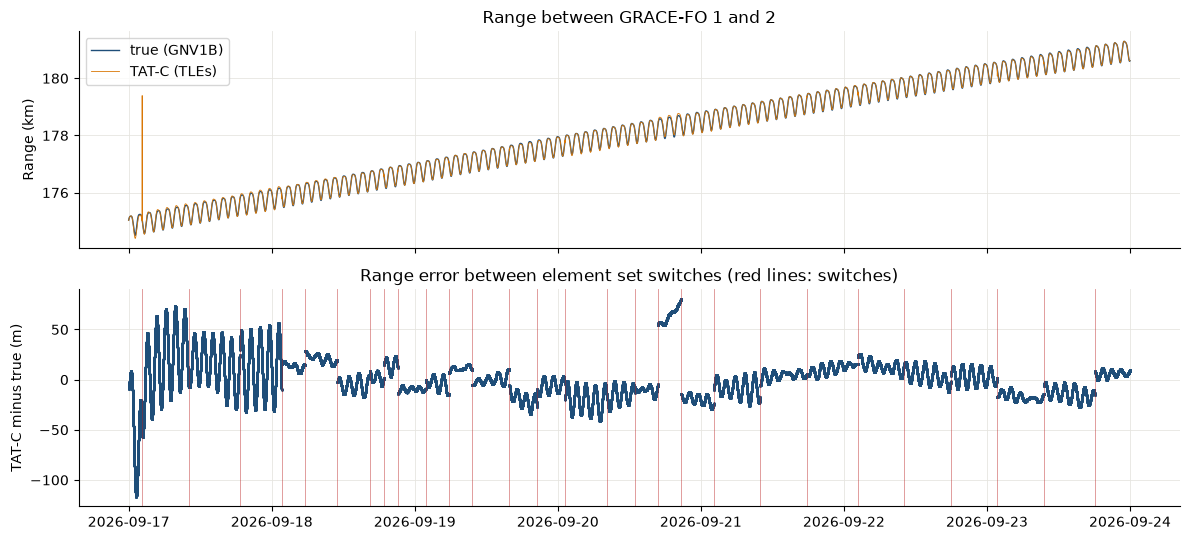

In [3]:
import matplotlib.pyplot as plt

from tatc.utils import align_element_switches

plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6}
)

true_range = np.linalg.norm(position["C"] - position["D"], axis=0)
predicted_range = np.linalg.norm(predicted["C"] - predicted["D"], axis=0)
range_error = predicted_range - true_range


def switch_times(orbit):
    """Times at which TAT-C switches element sets: midway between consecutive epochs."""
    epochs = [element.epoch for element in orbit.elements]
    return pd.DatetimeIndex([a + (b - a) / 2 for a, b in zip(epochs[:-1], epochs[1:])])


# switch intervals: from one satellite's switch to the other's nearest, during which the satellites'
# positions come from element sets of different epochs
switches = {k: switch_times(satellites[k].orbit) for k in "CD"}
intervals = [
    (min(a, b), max(a, b))
    for a in switches["C"][(switches["C"] > times[0]) & (switches["C"] < times[-1])]
    for b in [switches["D"][np.argmin(np.abs(switches["D"] - a))]]
]
at_switch = np.zeros(len(times), dtype=bool)
for a, b in intervals:
    at_switch |= (times >= a - pd.Timedelta(seconds=1)) & (times <= b + pd.Timedelta(seconds=1))
durations = np.array([(b - a).total_seconds() for a, b in intervals])
print(f"true range {true_range.min() / 1e3:.1f} to {true_range.max() / 1e3:.1f} km")
print(f"{len(intervals)} element set switches, each {durations.min():.1f} to {durations.max():.1f} s between the satellites")
peaks = np.array([np.abs(range_error[(times >= a) & (times <= b)]).max() for a, b in intervals])
print(
    f"largest range error during each switch: median {np.median(peaks):.0f} m, "
    f"{int((peaks > 1000).sum())} above 1 km, at most {peaks.max() / 1e3:.1f} km"
)

# the same orbits, switching element sets at common times
aligned = dict(zip("CD", align_element_switches([satellites["C"], satellites["D"]])))
common = set(aligned["C"].orbit.element_switch_times) == set(aligned["D"].orbit.element_switch_times)
print(
    f"aligned: {len(aligned['C'].orbit.elements)} and {len(aligned['D'].orbit.elements)} element sets, "
    f"{'common' if common else 'different'} switch times"
)
aligned_range = np.linalg.norm(earth_fixed_positions(aligned["C"]) - earth_fixed_positions(aligned["D"]), axis=0)
aligned_error = aligned_range - true_range
display(
    pd.DataFrame(
        {
            label: {
                "samples (s)": int(selected.sum()),
                "mean error (m)": error[selected].mean(),
                "standard deviation (m)": error[selected].std(),
                "95% |error| (m)": np.quantile(np.abs(error[selected]), 0.95),
                "max |error| (m)": np.abs(error[selected]).max(),
            }
            for label, error, selected in [
                ("between switches", range_error, ~at_switch),
                ("during switches", range_error, at_switch),
                ("during switches, aligned", aligned_error, at_switch),
                ("whole week, aligned", aligned_error, np.ones(len(times), dtype=bool)),
            ]
        }
    ).T.round(1)
)

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(times, true_range / 1e3, color="#1f4e79", lw=1, label="true (GNV1B)")
axes[0].plot(times, predicted_range / 1e3, color="#d97706", lw=0.6, label="TAT-C (TLEs)")
axes[0].set(ylabel="Range (km)", title="Range between GRACE-FO 1 and 2")
axes[0].legend(loc="upper left")
axes[1].plot(times[~at_switch], range_error[~at_switch], ".", color="#1f4e79", ms=0.5)
for a, _ in intervals:
    axes[1].axvline(a, color="#b91c1c", lw=0.6, alpha=0.5)
axes[1].set(ylabel="TAT-C minus true (m)", title="Range error between element set switches (red lines: switches)")
fig.tight_layout()
plt.show()

Between element set switches, TAT-C's range is accurate to 21 m (standard deviation), 47 m for 95% of the week, and 117 m at most, over separations of 174.5 to 181.3 km: some 25 times more accurate than the positions themselves, because the two satellites' errors cancel. The predicted range follows the true range closely, through its oscillation of about ±0.8 km each orbit and its drift of about 0.9 km a day as the satellites separate.

With independent switches, the element set switches are the exception. TAT-C switched element sets 28 times during the week, about every 6 hours, each time 23 s later for GRACE-FO 2 than for GRACE-FO 1. For those 23 s, the satellites' positions come from element sets of different epochs, whose errors no longer cancel: the range error reached 28 m (median) and, at one switch on 17 September, 4.3 km, where GRACE-FO 1's successive element sets differ by about that much along track.

Aligning the switches removes these errors. `align_element_switches` groups the two satellites' epochs into publication events, keeps the element sets of the events both satellites share (60 of each satellite's 63, dropping each satellite's duplicate and the sets only one satellite has, all outside this week), and switches both satellites midway between consecutive events. During the former switch intervals, the range error is then 80 m at most, as between switches, and over the whole week the range is accurate to 21 m (standard deviation) and 117 m at most.

## Test 3: Range Windows

`collect_space_observations` is run from GRACE-FO 1 to GRACE-FO 2 over the week with a `max_range` of 177, 178, or 179 km, or a `min_range` of 178 km, without the occlusion constraint and with the default `min_duration` (60 s), for the satellites switching element sets independently (by default) and at common times (aligned, as in Test 2). As the range drifts through each limit over a day or two, oscillating around each orbit, the windows open and close about twice per orbit. The true windows are found from the precise orbits, by interpolating the range every second, and each true window edge is paired with the nearest predicted edge of the same kind (start or end) within 15 minutes. For each true edge left unpaired, the table reports how far the true range goes past the limit before the nearer neighboring true edge, a measure of how marginal that window (or gap between windows) is.

In [4]:
from tatc.analysis import collect_space_observations

START = datetime(2026, 9, 17, tzinfo=timezone.utc)
END = datetime(2026, 9, 23, 23, 59, tzinfo=timezone.utc)
in_window = (times >= START) & (times <= END)
window_times = times[in_window]
seconds = (window_times - window_times[0]).total_seconds().to_numpy()


def true_edges(residual):
    """Window edges where a residual (sampled at window_times) changes sign, by linear interpolation:
    starts where it becomes non-positive, ends where it becomes positive."""
    inside = residual <= 0
    j = np.flatnonzero(inside[:-1] != inside[1:])
    crossing = seconds[j] - residual[j] / (residual[j + 1] - residual[j]) * (seconds[j + 1] - seconds[j])
    return pd.DataFrame({"time": window_times[0] + pd.to_timedelta(crossing, unit="s"), "start": inside[j + 1]})


def predicted_edges(windows):
    """Edges of predicted windows within the analysis period."""
    edges = pd.concat(
        [pd.DataFrame({"time": windows.start, "start": True}), pd.DataFrame({"time": windows.end, "start": False})]
    )
    inner = (edges.time > pd.Timestamp(START)) & (edges.time < pd.Timestamp(END))
    return edges[inner].sort_values("time", ignore_index=True)


def near_switch(edge_times, margin=30):
    """Whether each time is within margin (s) of an element set switch interval."""
    margin = pd.Timedelta(seconds=margin)
    return np.array([any(a - margin <= x <= b + margin for a, b in intervals) for x in edge_times])


def compare(truth, model, residual, tolerance=900):
    """Pairs each true edge with the nearest predicted edge of the same kind within tolerance (s)."""
    dt = (model.time.to_numpy()[None, :] - truth.time.to_numpy()[:, None]) / np.timedelta64(1, "s")
    dt = np.where(truth.start.to_numpy()[:, None] == model.start.to_numpy()[None, :], dt, np.inf)
    j = np.argmin(np.abs(dt), axis=1)
    offset = dt[np.arange(len(truth)), j]
    matched = np.abs(offset) <= tolerance
    extra = model.drop(index=np.unique(j[matched]))
    # for each unmatched true edge, how far the true residual goes past zero between it and the nearer
    # neighboring true edge (the other edge of a brief window or gap)
    bounds = pd.DatetimeIndex([window_times[0], *truth.time, window_times[-1]])
    excursion = []
    for k in np.flatnonzero(~matched):
        before, edge, after = bounds[k], bounds[k + 1], bounds[k + 2]
        other = before if edge - before < after - edge else after
        span = (window_times >= min(edge, other)) & (window_times <= max(edge, other))
        excursion.append(np.abs(residual[span]).max())
    return {
        "true edges": len(truth),
        "predicted edges": len(model),
        "matched": int(matched.sum()),
        "|time difference| median (s)": np.median(np.abs(offset[matched])),
        "95% (s)": np.quantile(np.abs(offset[matched]), 0.95),
        "max (s)": np.abs(offset[matched]).max(),
        "unmatched predicted edges": len(extra),
        "of which at switches": int(near_switch(extra.time).sum()),
        "unmatched true edges": int((~matched).sum()),
        "their largest true excursion (m)": max(excursion) if excursion else np.nan,
    }


range_in_window = true_range[in_window]
rows = {}
for label, pair in [("independent", satellites), ("aligned", aligned)]:
    for kind, value in [("max_range", 177e3), ("max_range", 178e3), ("max_range", 179e3), ("min_range", 178e3)]:
        residual = range_in_window - value if kind == "max_range" else value - range_in_window
        windows = collect_space_observations(
            pair["C"], START, END, to_satellites=pair["D"], min_grazing_altitude=None, **{kind: value}
        )
        rows[(label, f"{kind} = {value / 1e3:.0f} km")] = compare(
            true_edges(residual), predicted_edges(windows), residual
        )
pd.DataFrame(rows).T.rename_axis(["switch times", "limit"]).round(1)

true edges  predicted edges  matched  \
switch times limit                                                      
independent  max_range = 177 km        25.0             25.0     23.0   
             max_range = 178 km        25.0             27.0     23.0   
             max_range = 179 km        27.0             27.0     25.0   
             min_range = 178 km        25.0             27.0     23.0   
aligned      max_range = 177 km        25.0             23.0     23.0   
             max_range = 178 km        25.0             25.0     23.0   
             max_range = 179 km        27.0             25.0     25.0   
             min_range = 178 km        25.0             25.0     23.0   

                                 |time difference| median (s)  95% (s)  \
switch times limit                                                       
independent  max_range = 177 km                          16.1     49.3   
             max_range = 178 km                          42.8    156.9   
             max_range = 179 km                          20.1     56.7   
             min_range = 178 km                          42.8    156.9   
aligned      max_range = 177 km                          16.1     49.3   
             max_range = 178 km                          42.8    156.9   
             max_range = 179 km                          20.1     56.7   
             min_range = 178 km                          42.8    156.9   

                                 max (s)  unmatched predicted edges  \
switch times limit                                                    
independent  max_range = 177 km     60.6                        2.0   
             max_range = 178 km    165.3                        4.0   
             max_range = 179 km     64.4                        2.0   
             min_range = 178 km    165.3                        4.0   
aligned      max_range = 177 km     60.6                        0.0   
             max_range = 178 km    165.3                        2.0   
             max_range = 179 km     64.4                        0.0   
             min_range = 178 km    165.3                        2.0   

                                 of which at switches  unmatched true edges  \
switch times limit                                                            
independent  max_range = 177 km                   2.0                   2.0   
             max_range = 178 km                   2.0                   2.0   
             max_range = 179 km                   2.0                   2.0   
             min_range = 178 km                   2.0                   2.0   
aligned      max_range = 177 km                   0.0                   2.0   
             max_range = 178 km                   0.0                   2.0   
             max_range = 179 km                   0.0                   2.0   
             min_range = 178 km                   0.0                   2.0   

                                 their largest true excursion (m)  
switch times limit                                                 
independent  max_range = 177 km                               1.4  
             max_range = 178 km                              53.9  
             max_range = 179 km                               3.2  
             min_range = 178 km                              53.9  
aligned      max_range = 177 km                               1.4  
             max_range = 178 km                              53.9  
             max_range = 179 km                               3.2  
             min_range = 178 km                              53.9

`collect_space_observations` finds the windows when the range is within limits, with edges within 16 to 43 s (median) and 49 to 157 s (95th percentile) of the true times. The timing errors are large in seconds only because the range changes slowly, by 0.25 m/s (median) and at most 0.55 m/s, so a range error of about 20 m shifts the edges by about a minute, and more where the range turns near the limit. The windows differ in two ways:

* **Element set switches.** With independent switches, at every limit, the 4.3 km range error at the switch of 17 September creates a spurious gap of 23 s in a window (for `max_range`), or a spurious window (for `min_range`), although the true range was 2 to 4 km from the limit. With aligned switches, there is none.
* **Marginal windows.** At each limit, the true range enters one window (or gap between windows) by only 1.4 to 54 m, which the predicted range misses; at 178 km, the predicted range also opens one window (on 20 September, 21:01 to 21:08) that the true range misses by 2.8 m. Such windows are within the range accuracy of Test 2.

## Test 4: Occlusion Windows

The minimum WGS 84 geodetic altitude of the line of sight between the satellites, its tangent point, varies around each orbit, mostly with latitude, as the Earth's flattening lowers the surface toward the poles. `collect_space_observations` is run with a `min_grazing_altitude` of 450, 460, or 470 km (and no range limits), and its windows are compared with the true windows, found from the precise orbits as in Test 3. With its default `min_grazing_altitude` of 0, the line of sight is never occluded, and a single window should span the week.

In [5]:
from pyproj import Transformer

from tatc.utils import compute_tangent_point

TO_LLA = Transformer.from_crs("EPSG:4978", "EPSG:4979", always_xy=True)
# minimum WGS 84 geodetic altitude of the true line of sight: its tangent point, which lies between the
# satellites at their separation
tangent_point = compute_tangent_point(position["C"], position["D"] - position["C"])
true_altitude = np.asarray(TO_LLA.transform(*tangent_point)[2])[in_window]
print(f"true minimum altitude of the line of sight: {true_altitude.min() / 1e3:.1f} to {true_altitude.max() / 1e3:.1f} km")
everything = collect_space_observations(satellites["C"], START, END, to_satellites=satellites["D"])
print(f"default constraints (min_grazing_altitude = 0): {len(everything)} window(s), {everything.start.min()} to {everything.end.max()}")
rows = {}
for value in [450e3, 460e3, 470e3]:
    residual = value - true_altitude
    windows = collect_space_observations(satellites["C"], START, END, to_satellites=satellites["D"], min_grazing_altitude=value)
    rows[f"min_grazing_altitude = {value / 1e3:.0f} km"] = compare(true_edges(residual), predicted_edges(windows), residual)
pd.DataFrame(rows).T.round(1)

true minimum altitude of the line of sight: 444.7 to 481.3 km
default constraints (min_grazing_altitude = 0): 1 window(s), 2026-09-17 00:00:00+00:00 to 2026-09-23 23:59:00+00:00


,true edges,predicted edges,matched,|time difference| median (s),95% (s),max (s),unmatched predicted edges,of which at switches,unmatched true edges,their largest true excursion (m)
min_grazing_altitude = 450 km,431.0,431.0,431.0,6.3,15.9,47.0,0.0,0.0,0.0,NaN
min_grazing_altitude = 460 km,215.0,215.0,215.0,2.8,6.5,28.7,0.0,0.0,0.0,NaN
min_grazing_altitude = 470 km,215.0,215.0,215.0,2.5,6.4,31.3,0.0,0.0,0.0,NaN


The occlusion constraint is reproduced at altitude: every true window edge is predicted, and no others, at all three limits (215 to 431 edges over the week), within 2.5 to 6 s (median) and 6 to 16 s (95th percentile) of the true times. The minimum altitude of the line of sight changes much faster than the range, by up to 37 km in a quarter of an orbit as the Earth's flattening (21 km from equator to pole) and the orbit's eccentricity (about ±6 km) combine, so the satellites' position errors shift the edges by only a few seconds, and by up to 47 s where the altitude turns near the limit. The 450 km limit is crossed four times per orbit, the 460 and 470 km limits twice. The element set switches have no visible effect: the minimum altitude depends little on the satellites' separation along track. With the default `min_grazing_altitude` of 0, a single window spans the week.

## Summary

| Test | Result |
| --- | --- |
| 1. Orbits | Published orbits within 0.5 km along track (median; 4.7 km at most), 0.08 km radially, and 0.13 km cross track of the precise orbits; no offset in the Earth-fixed coordinates of `collect_orbit_track` |
| 2. Range | Within 21 m (standard deviation) and 117 m (at most) between element set switches; up to 4.3 km during the 23 s of each switch, unless the switches are aligned |
| 3. Range windows | Edges within 16 to 43 s (median), limited by the slow change of range; one spurious 23 s gap or window from an element set switch (none with aligned switches), and one marginal window per limit (within about 50 m of it) missed |
| 4. Occlusion windows | All 215 to 431 edges per limit predicted, and no others, within 2.5 to 6 s (median) |

**TAT-C's slant range and occlusion constraints are validated against GRACE-FO.** From published orbits, TAT-C computes the range between two satellites flying in formation to about 20 m, far better than their positions, and `collect_space_observations` finds the windows within range limits and above an altitude accordingly, at a fraction of a second of computation for a week.

**Element set switches in formations.** By default, TAT-C switches each satellite's element set midway between its epochs, independently for each satellite. When the satellites' element sets are published at slightly different times, as here and for most formations and constellations, their relative positions jump for the seconds between the switches, by up to the difference between successive element sets (here up to 4.3 km, for 23 s), and can create spurious windows or gaps when a range limit is near the true range. Analyses of satellites flying in formation should align their switches with `tatc.utils.align_element_switches`, which removes these jumps (Tests 2 and 3).

**Next steps:**

1. *Brief windows.* Test windows shorter than `min_duration`, such as close approaches between satellites (from CelesTrak's SOCRATES).
2. *Formations.* Compare the relative motion of TAT-C's generated formations (such as `TrainConstellation` and `MOGConstellation`) with that of GRACE-FO and other formations.

**Limitations.** This study covers one week and one pair of satellites in the same orbit at a nearly constant separation (175 to 181 km). The range accuracy reflects their common orbit errors, which cancel, and would be lower for satellites in different orbits.